============================================================
 MEGNet Training & Evaluation Script
============================================================

In [3]:
# ── Imports ──────────────────────────────────────────────────
import os
import pickle
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from megnet.models import MEGNetModel
from megnet.data.crystal import CrystalGraph

In [4]:
# ── Config ───────────────────────────────────────────────────
GRAPHS_PATH   = "heusler_graphs.pkl"
MODEL_DIR     = "callback"
CUTOFF        = 10          # Å  (MEGNet default is 5)
NFEAT_BOND    = 100
GAUSS_WIDTH   = 0.5
LR            = 1e-3
EPOCHS        = 100
BATCH_SIZE    = 64
PATIENCE      = 50          # MEGNet was 500 (exceeded EPOCHS)
RANDOM_STATE  = 42
TEST_SIZE = 0.20  

In [5]:
# ── 1. Load Graphs ───────────────────────────────────────────
with open(GRAPHS_PATH, "rb") as f:
    data = pickle.load(f)

graphs  = data["graphs"]
targets = data["targets"]

print(f"Graphs : {len(graphs)}")
print(f"Targets: {len(targets)}")
assert len(graphs) == len(targets), "Graph / target count mismatch!"

Graphs : 8166
Targets: 8166


In [6]:
# ── 2. Data Split ────────────────────────────────────────────
train_graphs, temp_graphs, train_targets, temp_targets = train_test_split(
    graphs, targets, test_size=TEST_SIZE, random_state=RANDOM_STATE
)
val_graphs, test_graphs, val_targets, test_targets = train_test_split(
    temp_graphs, temp_targets, test_size=0.5, random_state=RANDOM_STATE  
)

print(f"Train : {len(train_graphs)}")
print(f"Val   : {len(val_graphs)}")
print(f"Test  : {len(test_graphs)}")

Train : 6532
Val   : 817
Test  : 817


In [7]:
# ── 3. Build Model ───────────────────────────────────────────
centers = np.linspace(0, CUTOFF, NFEAT_BOND)
graph_converter = CrystalGraph(cutoff=CUTOFF)
model = MEGNetModel(
    graph_converter=graph_converter,
    centers=centers,
    width=GAUSS_WIDTH,
    lr=LR,
    loss="mse",
    metrics=["mae"],
)
print("Model initialised.")

C:\Users\taluk\anaconda3\envs\megnet_env\lib\site-packages\keras\initializers\initializers_v2.py:120: UserWarning: The initializer GlorotUniform is unseeded and being called multiple times, which will return identical values  each time (even if the initializer is unseeded). Please update your code to provide a seed to the initializer, or avoid using the same initalizer instance more than once.
  warnings.warn(


Model initialised.


C:\Users\taluk\anaconda3\envs\megnet_env\lib\site-packages\keras\optimizers\optimizer_v2\adam.py:114: UserWarning: The `lr` argument is deprecated, use `learning_rate` instead.
  super().__init__(name, **kwargs)


In [8]:
#Remove old checkpoints
#____________________________________________________

import shutil
import os

if os.path.exists("callback"):
    shutil.rmtree("callback")

os.makedirs("callback", exist_ok=True)

print("Fresh callback folder created")

Fresh callback folder created


In [9]:
#Remove old outputs
#____________________________________________________

files_to_remove = [
    "megnet_trained.h5",
    "megnet_results.json",
    "megnet_results.png"
]

for f in files_to_remove:
    if os.path.exists(f):
        os.remove(f)

print("Old outputs removed")

Old outputs removed


In [10]:
# ── 4. Train ─────────────────────────────────────────────────
history = model.train_from_graphs(
    train_graphs,
    train_targets,
    validation_graphs=val_graphs,
    validation_targets=val_targets,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    patience=PATIENCE,
    dirname=MODEL_DIR,
)

Epoch 1/100
1/1 [==============================] - 4s 4s/step


INFO:megnet.callbacks:
Epoch 00001: val_mae improved from inf to 0.26084, saving model to callback\val_mae_00001_0.260844.hdf5


103/103 [==============================] - 170s 1s/step - loss: 0.5176 - mae: 0.4753
Epoch 2/100
1/1 [==============================] - 1s 540ms/step


INFO:megnet.callbacks:
Epoch 00002: val_mae improved from 0.26084 to 0.24603, saving model to callback\val_mae_00002_0.246032.hdf5


103/103 [==============================] - 147s 1s/step - loss: 0.1292 - mae: 0.2568
Epoch 3/100
103/103 [==============================] - 142s 1s/step - loss: 0.1195 - mae: 0.2469
Epoch 4/100
1/1 [==============================] - 1s 536ms/step


...

103/103 [==============================] - 207s 2s/step - loss: 0.0219 - mae: 0.0969
Epoch 90/100
1/1 [==============================] - 1s 774ms/step


INFO:megnet.callbacks:
Epoch 00090: val_mae improved from 0.09755 to 0.09492, saving model to callback\val_mae_00090_0.094917.hdf5


103/103 [==============================] - 219s 2s/step - loss: 0.0204 - mae: 0.0912
Epoch 91/100
103/103 [==============================] - 218s 2s/step - loss: 0.0221 - mae: 0.0969
Epoch 92/100
103/103 [==============================] - 219s 2s/step - loss: 0.0196 - mae: 0.0913
Epoch 93/100
103/103 [==============================] - 222s 2s/step - loss: 0.0215 - mae: 0.0959
Epoch 94/100
103/103 [==============================] - 225s 2s/step - loss: 0.0208 - mae: 0.0920
Epoch 95/100
103/103 [==============================] - 226s 2s/step - loss: 0.0239 - mae: 0.1003
Epoch 96/100
103/103 [==============================] - 231s 2s/step - loss: 0.0201 - mae: 0.0909
Epoch 97/100
1/1 [==============================] - 1s 709ms/step


INFO:megnet.callbacks:
Epoch 00097: val_mae improved from 0.09492 to 0.09088, saving model to callback\val_mae_00097_0.090877.hdf5


103/103 [==============================] - 232s 2s/step - loss: 0.0189 - mae: 0.0885
Epoch 98/100
103/103 [==============================] - 235s 2s/step - loss: 0.0197 - mae: 0.0904
Epoch 99/100
103/103 [==============================] - 234s 2s/step - loss: 0.0195 - mae: 0.0909
Epoch 100/100
103/103 [==============================] - 237s 2s/step - loss: 0.0189 - mae: 0.0889


In [11]:
# ── 5. Load Best Checkpoint ──────────────────────────────────
if not os.path.isdir(MODEL_DIR):
    raise FileNotFoundError(
        f"Checkpoint directory '{MODEL_DIR}' not found. "
        "Make sure MEGNet's callback saved weights there."
    )
hdf5_files = [f for f in os.listdir(MODEL_DIR) if f.endswith(".hdf5")]
if not hdf5_files:
    raise FileNotFoundError(f"No .hdf5 checkpoints found in '{MODEL_DIR}'.")

print("Checkpoints found:")
for f in hdf5_files:
    print(f"  {f}")

# Robust sort: try parsing val-loss from filename, fall back to mtime
def parse_val_loss(fname):
    try:
        return float(fname.split("_")[-1].replace(".hdf5", ""))
    except ValueError:
        return float("inf")

hdf5_files.sort(key=parse_val_loss)
best_model_path = os.path.join(MODEL_DIR, hdf5_files[0])
print(f"\nBest checkpoint: {best_model_path}")

model.load_weights(best_model_path)
print("Best model weights loaded successfully.")

Checkpoints found:
  val_mae_00001_0.260844.hdf5
  val_mae_00002_0.246032.hdf5
  val_mae_00004_0.239642.hdf5
  val_mae_00005_0.230431.hdf5
  val_mae_00007_0.217696.hdf5
  val_mae_00008_0.215384.hdf5
  val_mae_00009_0.149650.hdf5
  val_mae_00011_0.142259.hdf5
  val_mae_00013_0.136223.hdf5
  val_mae_00014_0.134013.hdf5
  val_mae_00018_0.124420.hdf5
  val_mae_00034_0.117214.hdf5
  val_mae_00046_0.116941.hdf5
  val_mae_00055_0.112047.hdf5
  val_mae_00057_0.111408.hdf5
  val_mae_00066_0.111015.hdf5
  val_mae_00072_0.105910.hdf5
  val_mae_00089_0.097546.hdf5
  val_mae_00090_0.094917.hdf5
  val_mae_00097_0.090877.hdf5

Best checkpoint: callback\val_mae_00097_0.090877.hdf5
Best model weights loaded successfully.


In [12]:
# ── 5b. Save Best Model Weights ──────────────────────────────
model.save_weights("megnet_trained.h5")
print("Best weights saved to megnet_trained.h5")

Best weights saved to megnet_trained.h5


In [13]:
# ── 6. Predict ───────────────────────────────────────────────
preds  = model.predict_graphs(test_graphs)
y_pred = np.array(preds).flatten()
y_true = np.array(test_targets)

print(f"Test samples: {len(y_true)}")
assert len(y_true) == len(y_pred), "Prediction / target count mismatch!"

1/1 [==============================] - 1s 516ms/step
Test samples: 817


In [14]:
# ── 7. Evaluate ──────────────────────────────────────────────
import json

mae  = mean_absolute_error(y_true, y_pred)
mse  = mean_squared_error(y_true, y_pred)
rmse = np.sqrt(mse)
r2   = r2_score(y_true, y_pred)

print("\n=== MEGNet Results ===")
print(f"MAE  : {mae:.4f}")
print(f"MSE  : {mse:.4f}")
print(f"RMSE : {rmse:.4f}")
print(f"R²   : {r2:.4f}")

results = {
    "mae":  round(float(mae),  6),
    "mse":  round(float(mse),  6),
    "rmse": round(float(rmse), 6),
    "r2":   round(float(r2),   6),
    "n_test": int(len(y_true)),
}
with open("megnet_results.json", "w") as f:
    json.dump(results, f, indent=2)
print("Results saved to megnet_results.json")


=== MEGNet Results ===
MAE  : 0.0856
MSE  : 0.0186
RMSE : 0.1364
R²   : 0.9869
Results saved to megnet_results.json


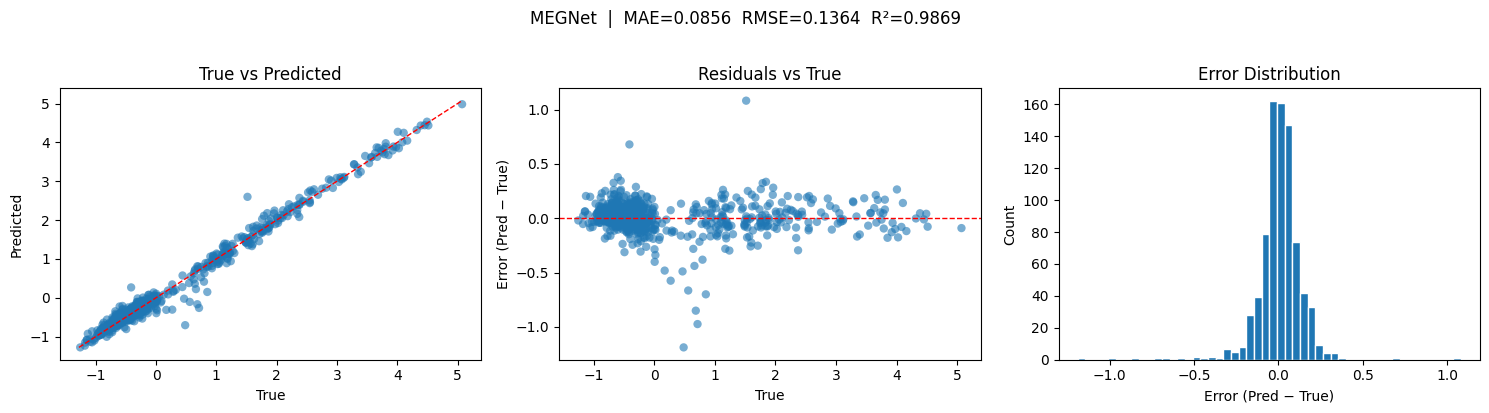

Plot saved to megnet_results.png


In [15]:
# ── 8. Plot ──────────────────────────────────────────────────
errors = y_pred - y_true
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# Parity plot
axes[0].scatter(y_true, y_pred, alpha=0.6, edgecolors="none")
lims = [min(y_true.min(), y_pred.min()), max(y_true.max(), y_pred.max())]
axes[0].plot(lims, lims, "r--", linewidth=1)
axes[0].set_xlabel("True")
axes[0].set_ylabel("Predicted")
axes[0].set_title("True vs Predicted")

# Residual plot
axes[1].scatter(y_true, errors, alpha=0.6, edgecolors="none")
axes[1].axhline(0, color="r", linestyle="--", linewidth=1)
axes[1].set_xlabel("True")
axes[1].set_ylabel("Error (Pred − True)")
axes[1].set_title("Residuals vs True")

# Error distribution
axes[2].hist(errors, bins=50, edgecolor="white")
axes[2].set_xlabel("Error (Pred − True)")
axes[2].set_ylabel("Count")
axes[2].set_title("Error Distribution")

plt.suptitle(f"MEGNet  |  MAE={mae:.4f}  RMSE={rmse:.4f}  R²={r2:.4f}", y=1.02)
plt.tight_layout()
plt.savefig("megnet_results.png", dpi=300, bbox_inches="tight")
plt.show()
print("Plot saved to megnet_results.png")